# Classificador de imagens com CNN (CIFAR-10)

Neste notebook treinamos uma **Rede Neural Convolucional (CNN)** para classificar imagens da base
**CIFAR-10**: 60.000 imagens coloridas de 32x32 pixels divididas em 10 classes
(avião, automóvel, pássaro, gato, cervo, cachorro, sapo, cavalo, navio e caminhão).

Fluxo do notebook:

1. carregar e normalizar as imagens;
2. visualizar alguns exemplos;
3. montar a CNN (com data augmentation, batch normalization e dropout);
4. treinar com early stopping e redução da learning rate;
5. avaliar no conjunto de teste e visualizar previsões.

## Importações

In [3]:
# Biblioteca para operações numéricas
import numpy as np

# Para visualização
import matplotlib.pyplot as plt

# Interface de alto nível do TensorFlow para construir redes neurais
from tensorflow import keras

# Camadas da rede
from tensorflow.keras.layers import (
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    Input,
    MaxPooling2D,
)

# Camadas de data augmentation (ficam ativas apenas durante o treino)
from tensorflow.keras.layers import RandomFlip, RandomTranslation

# Callbacks para controlar o treino
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Semente fixa para deixar o resultado reproduzível
keras.utils.set_random_seed(42)

## Carregar a base de dados CIFAR-10

O Keras já traz a CIFAR-10 separada em treino (50.000 imagens) e teste (10.000 imagens).
Os pixels vão de 0 a 255; dividimos por 255 para deixar tudo entre 0 e 1, o que ajuda o treino.

In [4]:
# Carregar a base CIFAR-10 (o download acontece na primeira execução)
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

# Normalizar os pixels para o intervalo [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Os rótulos vêm como coluna (N, 1); flatten deixa como vetor (N,)
y_train = y_train.flatten()
y_test = y_test.flatten()

# Nome de cada classe, na ordem dos rótulos 0 a 9
class_names = [
    "avião", "automóvel", "pássaro", "gato", "cervo",
    "cachorro", "sapo", "cavalo", "navio", "caminhão",
]

print(f"Formato de X_train: {X_train.shape}")
print(f"Formato de y_train: {y_train.shape}")
print(f"Formato de X_test: {X_test.shape}")
print(f"Formato de y_test: {y_test.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1452s 9us/step
Formato de X_train: (50000, 32, 32, 3)
Formato de y_train: (50000,)
Formato de X_test: (10000, 32, 32, 3)
Formato de y_test: (10000,)


## Plotar algumas imagens

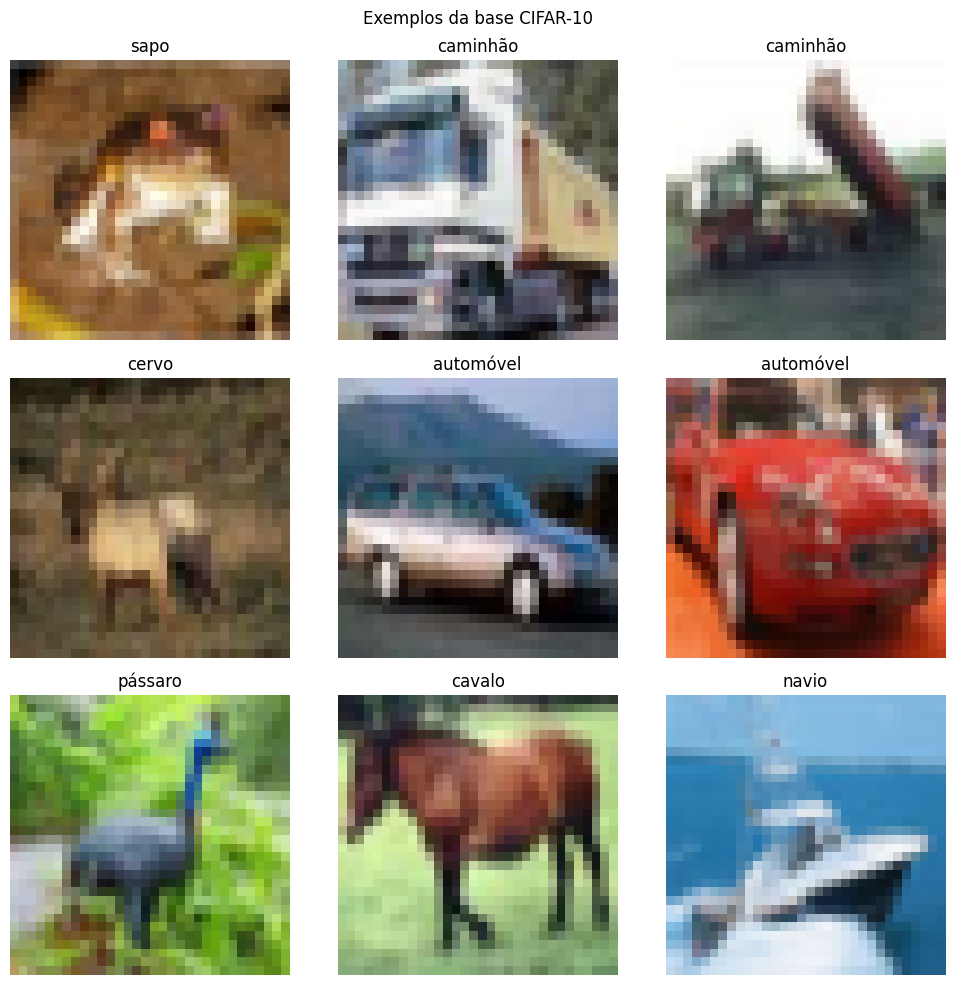

In [5]:
# Mostra as 9 primeiras imagens de treino com o nome da classe
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.suptitle("Exemplos da base CIFAR-10")
plt.tight_layout()
plt.show()

## Criação do modelo CNN

A rede tem três blocos convolucionais. Cada bloco:

- aplica duas camadas `Conv2D` (extraem padrões como bordas, texturas e formas);
- usa `BatchNormalization` para estabilizar e acelerar o treino;
- reduz o tamanho da imagem pela metade com `MaxPooling2D`;
- aplica `Dropout` para diminuir o overfitting.

O número de filtros dobra a cada bloco (32 → 64 → 128), porque padrões mais complexos precisam de
mais filtros. No final, `Flatten` transforma os mapas em um vetor e as camadas `Dense` fazem a
classificação. A saída tem 10 neurônios com `softmax` (uma probabilidade por classe).

Antes dos blocos entra o **data augmentation**: espelhamento horizontal e pequenos deslocamentos
geram variações das imagens a cada época, o que ajuda o modelo a generalizar.

In [6]:
model = keras.Sequential()

# Camada de entrada: imagens 32x32 com 3 canais (RGB)
model.add(Input(shape=(32, 32, 3)))

# Data augmentation: espelhamento horizontal e deslocamento de até 10%
model.add(RandomFlip("horizontal"))
model.add(RandomTranslation(height_factor=0.1, width_factor=0.1))

# Bloco 1 (padding="same" mantém o tamanho da imagem após a convolução)
model.add(Conv2D(filters=32, kernel_size=(3, 3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(Conv2D(filters=32, kernel_size=(3, 3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))  # 32x32 -> 16x16
model.add(Dropout(0.2))

# Bloco 2
model.add(Conv2D(filters=64, kernel_size=(3, 3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(Conv2D(filters=64, kernel_size=(3, 3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))  # 16x16 -> 8x8
model.add(Dropout(0.3))

# Bloco 3
model.add(Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))  # 8x8 -> 4x4
model.add(Dropout(0.4))

# Transição CNN -> Dense (camadas totalmente conectadas)
model.add(Flatten())
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(10, activation="softmax"))  # uma probabilidade para cada classe

# Compilação do modelo
# sparse_categorical_crossentropy: os rótulos são inteiros (0 a 9), não one-hot
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,362 (2.11 MB)

 Trainable params: 551,466 (2.10 MB)

 Non-trainable params: 896 (3.50 KB)

## Treinar a rede

Usamos 20% do treino como validação e dois callbacks:

- `EarlyStopping`: para o treino quando a `val_loss` deixa de melhorar por 8 épocas e volta para os melhores pesos;
- `ReduceLROnPlateau`: corta a learning rate pela metade quando a `val_loss` fica parada por 3 épocas.

In [7]:
# Para o treino quando a val_loss para de melhorar e restaura os melhores pesos
early_stopping = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

# Reduz a taxa de aprendizado pela metade quando a val_loss estagna
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

history = model.fit(
    X_train,
    y_train,
    epochs=60,
    batch_size=64,
    validation_split=0.2,  # 20% do treino vira validação
    callbacks=[early_stopping, reduce_lr],
)

Epoch 1/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.2898 - loss: 1.9311 - val_accuracy: 0.4314 - val_loss: 1.5158 - learning_rate: 0.0010
Epoch 2/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.4097 - loss: 1.5963 - val_accuracy: 0.4590 - val_loss: 1.5299 - learning_rate: 0.0010
Epoch 3/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.4963 - loss: 1.3926 - val_accuracy: 0.5797 - val_loss: 1.1901 - learning_rate: 0.0010
Epoch 4/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5556 - loss: 1.2470 - val_accuracy: 0.6239 - val_loss: 1.0716 - learning_rate: 0.0010
Epoch 5/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6022 - loss: 1.1363 - val_accuracy: 0.6633 - val_loss: 0.9411 - learning_rate: 0.0010
Epoch 6/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6391 - loss: 1.0494 - val_accuracy: 0.6631 - val_loss: 0.9862 - learning_rate: 0.0010
Epoch 7/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6658 - l

## Plot da acurácia e da loss

As curvas mostram se o modelo está aprendendo e se há overfitting
(treino melhorando enquanto a validação piora).

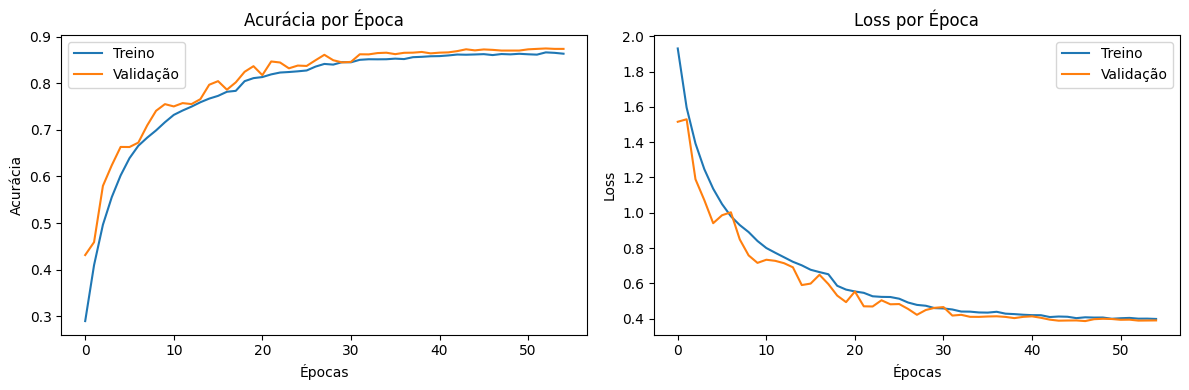

In [8]:
plt.figure(figsize=(12, 4))

# Acurácia de treino e validação por época
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Treino")
plt.plot(history.history["val_accuracy"], label="Validação")
plt.title("Acurácia por Época")
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.legend()

# Loss de treino e validação por época
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Treino")
plt.plot(history.history["val_loss"], label="Validação")
plt.title("Loss por Época")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## Avaliação no conjunto de teste

O conjunto de teste não foi usado no treino, então mostra o desempenho real em imagens novas.

In [9]:
test_loss, test_acc = model.evaluate(X_test, y_test)

print(f"Acurácia no conjunto de teste: {test_acc:.4f}")
print(f"Loss no conjunto de teste: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8627 - loss: 0.4279
Acurácia no conjunto de teste: 0.8627
Loss no conjunto de teste: 0.4279


## Previsões em imagens do teste

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step


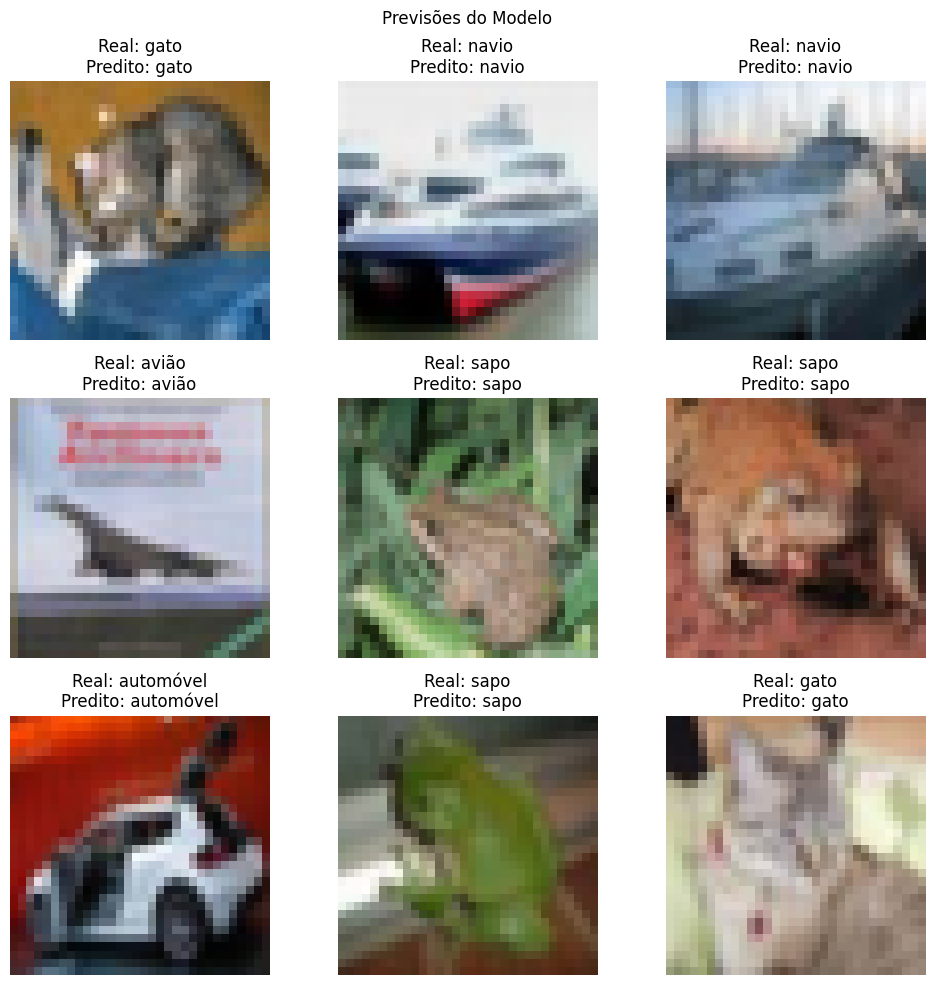

In [10]:
# Probabilidades das 10 classes para as 9 primeiras imagens de teste
pred_probs = model.predict(X_test[:9])

# A classe prevista é a de maior probabilidade
pred_labels = np.argmax(pred_probs, axis=1)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i])
    real = class_names[y_test[i]]
    pred = class_names[pred_labels[i]]
    plt.title(f"Real: {real}\nPredito: {pred}")
    plt.axis("off")
plt.suptitle("Previsões do Modelo")
plt.tight_layout()
plt.show()